<a href="https://colab.research.google.com/github/I7411/TH_BIGDATA/blob/main/HuynhThanhMinhTam_2001230789_BT2_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install pyspark

import os, time, shutil, statistics
import pandas as pd
import matplotlib.pyplot as plt
import psutil
from pyspark.sql import SparkSession, functions as F, types as T
from google.colab import drive

drive.mount("/content/drive")

spark = (SparkSession.builder
         .master("local[2]")
         .appName("Lab04_Bai2_Freight_Shipments")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.sql.adaptive.enabled", "true")
         .getOrCreate())

print("=== CẤU HÌNH HỆ THỐNG ===")
print("Spark version:", spark.version)
print("Master:", spark.sparkContext.master)
print("CPU cores:", os.cpu_count())
print("RAM (GiB):", round(psutil.virtual_memory().total / 2**30, 2))

NAME = "Lab04_Bai2_US_Freight_Shipments.csv"
SOURCE = f"/content/drive/MyDrive/BigData_Lab04/{NAME}"
DATA_PATH = f"/content/{NAME}"

assert os.path.exists(SOURCE), f"Không tìm thấy tệp {SOURCE}"
shutil.copy2(SOURCE, DATA_PATH)
print("Input file (MiB):", round(os.path.getsize(DATA_PATH) / 2**20, 2))

Mounted at /content/drive
=== CẤU HÌNH HỆ THỐNG ===
Spark version: 4.0.5
Master: local[2]
CPU cores: 2
RAM (GiB): 12.67
Input file (MiB): 52.09


In [2]:
# Định nghĩa tường minh Schema 27 cột
SHIPMENT_SCHEMA = T.StructType([
    T.StructField("shipment_id", T.StringType()),
    T.StructField("ship_date", T.StringType()),
    T.StructField("client_id", T.LongType()),
    T.StructField("client_segment", T.StringType()),
    T.StructField("client_contract", T.StringType()),
    T.StructField("origin_hub_id", T.StringType()),
    T.StructField("origin_city", T.StringType()),
    T.StructField("origin_state", T.StringType()),
    T.StructField("destination_hub_id", T.StringType()),
    T.StructField("destination_city", T.StringType()),
    T.StructField("destination_state", T.StringType()),
    T.StructField("carrier_id", T.StringType()),
    T.StructField("carrier_name", T.StringType()),
    T.StructField("service_level", T.StringType()),
    T.StructField("package_type", T.StringType()),
    T.StructField("weight_kg", T.DoubleType()),
    T.StructField("distance_km", T.DoubleType()),
    T.StructField("promised_days", T.IntegerType()),
    T.StructField("actual_days", T.IntegerType()),
    T.StructField("on_time", T.StringType()),
    T.StructField("fuel_fee_usd", T.DecimalType(14, 2)),
    T.StructField("base_fee_usd", T.DecimalType(14, 2)),
    T.StructField("insurance_fee_usd", T.DecimalType(14, 2)),
    T.StructField("total_charge_usd", T.DecimalType(16, 2)),
    T.StructField("scanner_profile", T.StringType()),
    T.StructField("route_tag_color", T.StringType()),
    T.StructField("dispatch_note", T.StringType())
])

raw_df = spark.read.option("header", "true").schema(SHIPMENT_SCHEMA).csv(DATA_PATH)

shipments = (raw_df
    .withColumn("ship_date", F.to_date("ship_date"))
    .withColumn("ship_year", F.year("ship_date"))
    .withColumn("ship_month", F.month("ship_date"))
    # Chuẩn hóa on_time về boolean (hỗ trợ cả 'True'/'1'/'Yes')
    .withColumn("on_time_bool", F.lower(F.trim(F.col("on_time"))).isin("true", "1", "yes"))
)

total_rows = shipments.count()
orig_cols = len(raw_df.columns)
unique_shipments = shipments.select("shipment_id").distinct().count()
date_bounds = shipments.agg(F.min("ship_date").alias("min_d"), F.max("ship_date").alias("max_d")).first()
file_mib = round(os.path.getsize(DATA_PATH) / 2**20, 2)

# Kiểm tra vi phạm 1: total_charge_usd != fuel_fee_usd + base_fee_usd + insurance_fee_usd
fee_violations = shipments.filter(
    F.col("total_charge_usd") != (F.col("fuel_fee_usd") + F.col("base_fee_usd") + F.col("insurance_fee_usd"))
).count()

# Kiểm tra vi phạm 2: on_time_bool != (actual_days <= promised_days)
sla_violations = shipments.filter(
    F.col("on_time_bool") != (F.col("actual_days") <= F.col("promised_days"))
).count()

print(f"Tổng số dòng: {total_rows:,} | Số cột gốc: {orig_cols}")
print(f"Số vận đơn duy nhất (shipment_id): {unique_shipments:,}")
print(f"Khoảng ngày giao hàng: từ {date_bounds['min_d']} đến {date_bounds['max_d']}")
print(f"Dung lượng tệp: {file_mib} MiB")
print(f"Số bản ghi vi phạm tổng phí (total_charge_usd): {fee_violations}")
print(f"Số bản ghi vi phạm trạng thái đúng hạn (on_time): {sla_violations}")

Tổng số dòng: 300,000 | Số cột gốc: 27
Số vận đơn duy nhất (shipment_id): 300,000
Khoảng ngày giao hàng: từ 2025-01-01 đến 2026-06-30
Dung lượng tệp: 52.09 MiB
Số bản ghi vi phạm tổng phí (total_charge_usd): 300000
Số bản ghi vi phạm trạng thái đúng hạn (on_time): 0


In [3]:
CLIENT_COLS = ["client_id", "client_segment", "client_contract"]
CARRIER_COLS = ["carrier_id", "carrier_name"]

# Xây dựng bảng Dimension trung tâm phân loại (Hub) hợp nhất từ cả origin_hub và destination_hub
origin_hubs = shipments.select(
    F.col("origin_hub_id").alias("hub_id"),
    F.col("origin_city").alias("city"),
    F.col("origin_state").alias("state")
)
dest_hubs = shipments.select(
    F.col("destination_hub_id").alias("hub_id"),
    F.col("destination_city").alias("city"),
    F.col("destination_state").alias("state")
)
all_hubs = origin_hubs.unionByName(dest_hubs).distinct()

# Kiểm tra tính nhất quán khóa (profiles == keys) cho từng bảng Dimension
d_clients = shipments.select(*CLIENT_COLS).distinct()
d_carriers = shipments.select(*CARRIER_COLS).distinct()
d_hubs = all_hubs

for name, df_dim, key_col in [
    ("d_clients", d_clients, "client_id"),
    ("d_carriers", d_carriers, "carrier_id"),
    ("d_hubs", d_hubs, "hub_id")
]:
    profiles = df_dim.count()
    keys = df_dim.select(key_col).distinct().count()
    dup_risk = profiles - keys
    print(f"{name}: khóa='{key_col}' | số khóa={keys:,} | số dòng profile={profiles:,} | khóa trùng thuộc tính={dup_risk}")
    assert profiles == keys, f"Lỗi xung đột thuộc tính trên khóa {key_col} của {name}!"

# Bảng Fact vận đơn (loại bỏ các cột mô tả đã tách sang Dimension và cột nhiễu)
f_shipments = shipments.select(
    "shipment_id", "ship_date", "ship_year", "ship_month",
    "client_id", "carrier_id", "origin_hub_id", "destination_hub_id",
    "service_level", "package_type",
    "weight_kg", "distance_km", "promised_days", "actual_days", "on_time_bool",
    "fuel_fee_usd", "base_fee_usd", "insurance_fee_usd", "total_charge_usd"
)

STAGE_DIR = "/content/lab04_bai2_tables"
tables = {
    "f_shipments": f_shipments,
    "d_clients": d_clients,
    "d_carriers": d_carriers,
    "d_hubs": d_hubs
}

for t_name, df_tbl in tables.items():
    t_path = f"{STAGE_DIR}/{t_name}"
    df_tbl.write.mode("overwrite").parquet(t_path)
    spark.read.parquet(t_path).createOrReplaceTempView(t_name)
    print(f"Đã lưu bảng {t_name}: {spark.table(t_name).count():,} dòng")

# Kiểm tra JOIN đầy đủ (kể cả JOIN 2 lần với d_hubs cho origin và destination) không làm nhân bản dòng
joined_count = spark.sql("""
SELECT COUNT(*) AS n
FROM f_shipments s
JOIN d_clients c ON s.client_id = c.client_id
JOIN d_carriers cr ON s.carrier_id = cr.carrier_id
JOIN d_hubs ho ON s.origin_hub_id = ho.hub_id
JOIN d_hubs hd ON s.destination_hub_id = hd.hub_id
""").first()["n"]

fact_count = spark.table("f_shipments").count()
print(f"Số dòng trước JOIN: {fact_count:,} | Số dòng sau JOIN: {joined_count:,} | Chênh lệch (nhân đôi): {joined_count - fact_count}")
assert joined_count == fact_count, "Phát hiện sai lệch số dòng sau JOIN!"

d_clients: khóa='client_id' | số khóa=3,575 | số dòng profile=3,575 | khóa trùng thuộc tính=0
d_carriers: khóa='carrier_id' | số khóa=6 | số dòng profile=6 | khóa trùng thuộc tính=0
d_hubs: khóa='hub_id' | số khóa=12 | số dòng profile=12 | khóa trùng thuộc tính=0
Đã lưu bảng f_shipments: 300,000 dòng
Đã lưu bảng d_clients: 3,575 dòng
Đã lưu bảng d_carriers: 6 dòng
Đã lưu bảng d_hubs: 12 dòng
Số dòng trước JOIN: 300,000 | Số dòng sau JOIN: 300,000 | Chênh lệch (nhân đôi): 0


In [4]:
# Câu 3: Doanh thu & mức phí trung bình theo service_level và client_segment (HAVING >= 1.000 vận đơn)
q3_sql = """
SELECT s.service_level,
       c.client_segment,
       COUNT(s.shipment_id) AS total_shipments,
       ROUND(SUM(s.total_charge_usd), 2) AS total_revenue_usd,
       ROUND(AVG(s.total_charge_usd), 2) AS avg_charge_usd
FROM f_shipments s
JOIN d_clients c ON s.client_id = c.client_id
GROUP BY s.service_level, c.client_segment
HAVING COUNT(s.shipment_id) >= 1000
ORDER BY total_revenue_usd DESC
"""
print("=== CÂU 3: DOANH THU THEO SERVICE_LEVEL & CLIENT_SEGMENT ===")
spark.sql(q3_sql).show(50, truncate=False)

# Câu 4: JOIN >= 3 bảng tìm TOP 5 tuyến (origin_state -> destination_state, carrier_name) có >= 100 vận đơn
q4_sql = """
SELECT ho.state AS origin_state,
       hd.state AS destination_state,
       cr.carrier_name,
       COUNT(s.shipment_id) AS shipment_count,
       ROUND(SUM(s.total_charge_usd), 2) AS total_fee_usd
FROM f_shipments s
JOIN d_hubs ho ON s.origin_hub_id = ho.hub_id
JOIN d_hubs hd ON s.destination_hub_id = hd.hub_id
JOIN d_carriers cr ON s.carrier_id = cr.carrier_id
GROUP BY ho.state, hd.state, cr.carrier_name
HAVING COUNT(s.shipment_id) >= 100
ORDER BY total_fee_usd DESC
LIMIT 5
"""
print("=== CÂU 4: TOP 5 TUYẾN VẬN CHUYỂN CÓ DOANH THU CAO NHẤT (>= 100 VẬN ĐƠN) ===")
spark.sql(q4_sql).show(truncate=False)

# Câu 5: Window Function xếp hạng TOP 3 hãng vận chuyển đúng hạn cao nhất trong từng destination_state
q5_sql = """
WITH state_carrier_stats AS (
    SELECT hd.state AS destination_state,
           cr.carrier_id,
           cr.carrier_name,
           COUNT(s.shipment_id) AS total_shipments,
           SUM(CASE WHEN s.on_time_bool THEN 1 ELSE 0 END) AS on_time_shipments,
           ROUND(SUM(CASE WHEN s.on_time_bool THEN 1.0 ELSE 0.0 END) / COUNT(s.shipment_id), 6) AS on_time_rate
    FROM f_shipments s
    JOIN d_hubs hd ON s.destination_hub_id = hd.hub_id
    JOIN d_carriers cr ON s.carrier_id = cr.carrier_id
    GROUP BY hd.state, cr.carrier_id, cr.carrier_name
    HAVING COUNT(s.shipment_id) >= 100
), ranked_carriers AS (
    SELECT *,
           ROW_NUMBER() OVER (
               PARTITION BY destination_state
               ORDER BY on_time_rate DESC, total_shipments DESC, carrier_id ASC
           ) AS rank_in_state
    FROM state_carrier_stats
)
SELECT destination_state, rank_in_state, carrier_id, carrier_name,
       total_shipments, ROUND(on_time_rate * 100, 2) AS on_time_pct
FROM ranked_carriers
WHERE rank_in_state <= 3
ORDER BY destination_state ASC, rank_in_state ASC
"""
print("=== CÂU 5: TOP 3 HÃNG VẬN CHUYỂN ĐÚNG HẠN THEO DESTINATION_STATE (HIỂN THỊ >= 5 BANG) ===")
spark.sql(q5_sql).show(21, truncate=False)

=== CÂU 3: DOANH THU THEO SERVICE_LEVEL & CLIENT_SEGMENT ===
+-------------+--------------+---------------+-----------------+--------------+
|service_level|client_segment|total_shipments|total_revenue_usd|avg_charge_usd|
+-------------+--------------+---------------+-----------------+--------------+
|Economy      |Retail        |28610          |27144.00         |0.95          |
|Standard     |Retail        |28614          |26974.00         |0.94          |
|Express      |Retail        |25767          |24312.00         |0.94          |
|Economy      |Manufacturing |24971          |23689.00         |0.95          |
|Economy      |Technology    |24944          |23681.00         |0.95          |
|Economy      |Healthcare    |24923          |23640.00         |0.95          |
|Standard     |Manufacturing |24962          |23547.00         |0.94          |
|Standard     |Technology    |24961          |23537.00         |0.94          |
|Standard     |Healthcare    |24911          |23508.00     

In [5]:
print("=== CÂU 6A: PHYSICAL PLAN CỦA TRUY VẤN JOIN + GROUP BY (CÂU 4) ===")
spark.sql(q4_sql).explain(mode="formatted")

print("\n=== CÂU 6B: PHYSICAL PLAN CỦA TRUY VẤN WINDOW FUNCTION (CÂU 5) ===")
spark.sql(q5_sql).explain(mode="formatted")

=== CÂU 6A: PHYSICAL PLAN CỦA TRUY VẤN JOIN + GROUP BY (CÂU 4) ===
== Physical Plan ==
AdaptiveSparkPlan (23)
+- TakeOrderedAndProject (22)
   +- Filter (21)
      +- HashAggregate (20)
         +- Exchange (19)
            +- HashAggregate (18)
               +- Project (17)
                  +- BroadcastHashJoin Inner BuildRight (16)
                     :- Project (12)
                     :  +- BroadcastHashJoin Inner BuildRight (11)
                     :     :- Project (7)
                     :     :  +- BroadcastHashJoin Inner BuildRight (6)
                     :     :     :- Filter (2)
                     :     :     :  +- Scan parquet  (1)
                     :     :     +- BroadcastExchange (5)
                     :     :        +- Filter (4)
                     :     :           +- Scan parquet  (3)
                     :     +- BroadcastExchange (10)
                     :        +- Filter (9)
                     :           +- Scan parquet  (8)
                     

In [6]:
def benchmark_sql(query, repeats=3):
    spark.sql(query).collect() # Warm-up ngoài phép đo
    times = []
    res = None
    for _ in range(repeats):
        t0 = time.perf_counter()
        res = spark.sql(query).collect()
        times.append(time.perf_counter() - t0)
    return statistics.median(times), times, res

# --- CÂU 7: SO SÁNH REGULAR JOIN VS BROADCAST JOIN ---
JOIN_BASE = """
SELECT ho.state AS origin_state,
       cr.carrier_name,
       COUNT(*) AS cnt,
       ROUND(SUM(s.total_charge_usd), 2) AS total_usd
FROM f_shipments s
JOIN d_hubs ho ON s.origin_hub_id = ho.hub_id
JOIN d_carriers cr ON s.carrier_id = cr.carrier_id
GROUP BY ho.state, cr.carrier_name
ORDER BY ho.state, cr.carrier_name
"""

JOIN_BROADCAST = JOIN_BASE.replace(
    "SELECT ho.state", "SELECT /*+ BROADCAST(ho, cr) */ ho.state", 1
)

old_aqe = spark.conf.get("spark.sql.adaptive.enabled")
old_bcast = spark.conf.get("spark.sql.autoBroadcastJoinThreshold")

# Tắt AQE và autoBroadcast để quan sát rạch ròi 2 chiến lược
spark.conf.set("spark.sql.adaptive.enabled", "false")
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1")

print("Cấu hình thử nghiệm JOIN: adaptive.enabled =", spark.conf.get("spark.sql.adaptive.enabled"),
      "| autoBroadcastJoinThreshold =", spark.conf.get("spark.sql.autoBroadcastJoinThreshold"))

t_reg, raw_reg, rows_reg = benchmark_sql(JOIN_BASE, repeats=3)
t_bcast, raw_bcast, rows_bcast = benchmark_sql(JOIN_BROADCAST, repeats=3)

assert rows_reg == rows_bcast, "Kết quả Regular JOIN và Broadcast JOIN không khớp!"

# Khôi phục cấu hình mặc định
spark.conf.set("spark.sql.adaptive.enabled", old_aqe)
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", old_bcast)

print(f"Regular JOIN   -> các lượt: {[round(x, 4) for x in raw_reg]} | Trung vị: {t_reg:.4f}s")
print(f"Broadcast JOIN -> các lượt: {[round(x, 4) for x in raw_bcast]} | Trung vị: {t_bcast:.4f}s")

# --- CÂU 8: PARQUET KHÔNG PHÂN VÙNG VS PHÂN VÙNG THEO NĂM/THÁNG ---
PART_PATH = "/content/lab04_bai2_shipments_partitioned"
(spark.table("f_shipments").write.mode("overwrite")
      .partitionBy("ship_year", "ship_month")
      .parquet(PART_PATH))

spark.read.parquet(PART_PATH).createOrReplaceTempView("f_shipments_part")

# Chọn tháng mục tiêu (lấy tự động tháng có dữ liệu từ bảng fact để đảm bảo không rỗng)
sample_ym = spark.sql("SELECT ship_year, ship_month FROM f_shipments LIMIT 1").first()
TARGET_Y, TARGET_M = sample_ym["ship_year"], sample_ym["ship_month"]

Q_UNPART = f"""
SELECT COUNT(*) AS total_shipments,
       ROUND(SUM(total_charge_usd), 2) AS total_fee_usd
FROM f_shipments
WHERE ship_year = {TARGET_Y} AND ship_month = {TARGET_M}
"""
Q_PART = Q_UNPART.replace("FROM f_shipments", "FROM f_shipments_part")

print(f"\n=== PLAN PARTITION PRUNING (THÁNG {TARGET_M}/{TARGET_Y}) ===")
spark.sql(Q_PART).explain(mode="formatted")

t_unpart, raw_unpart, rows_unpart = benchmark_sql(Q_UNPART, repeats=3)
t_part, raw_part, rows_part = benchmark_sql(Q_PART, repeats=3)

assert rows_unpart == rows_part, "Kết quả Parquet unpartitioned và partitioned không khớp!"
print(f"Parquet Unpartitioned -> Trung vị: {t_unpart:.4f}s | Kết quả: {rows_unpart[0]}")
print(f"Parquet Partitioned   -> Trung vị: {t_part:.4f}s | Kết quả: {rows_part[0]}")

# --- CÂU 9: KHẢO SÁT CACHE VỚI 2 TRUY VẤN TỔNG HỢP LẶP LẠI ---
Q_CACHE_1 = """
SELECT service_level, COUNT(*) AS cnt, ROUND(SUM(total_charge_usd), 2) AS rev
FROM f_shipments GROUP BY service_level ORDER BY service_level
"""
Q_CACHE_2 = """
SELECT package_type, ROUND(AVG(weight_kg), 2) AS avg_w, ROUND(AVG(actual_days), 2) AS avg_d
FROM f_shipments GROUP BY package_type ORDER BY package_type
"""

t_nc1, _, r_nc1 = benchmark_sql(Q_CACHE_1, repeats=3)
t_nc2, _, r_nc2 = benchmark_sql(Q_CACHE_2, repeats=3)
t_nocache_total = t_nc1 + t_nc2

# Materialize cache
t_mat0 = time.perf_counter()
spark.catalog.cacheTable("f_shipments")
spark.table("f_shipments").count()
t_materialize = time.perf_counter() - t_mat0

t_c1, _, r_c1 = benchmark_sql(Q_CACHE_1, repeats=3)
t_c2, _, r_c2 = benchmark_sql(Q_CACHE_2, repeats=3)
t_cache_total = t_c1 + t_c2

assert r_nc1 == r_c1 and r_nc2 == r_c2, "Kết quả trước và sau cache không khớp!"

# Giải phóng bộ nhớ sau thí nghiệm
spark.catalog.uncacheTable("f_shipments")

print(f"\nThời gian materialize cache: {t_materialize:.4f}s")
print(f"Tổng 2 truy vấn (Không Cache): {t_nocache_total:.4f}s (Q1={t_nc1:.4f}s, Q2={t_nc2:.4f}s)")
print(f"Tổng 2 truy vấn (Đã Cache):    {t_cache_total:.4f}s (Q1={t_c1:.4f}s, Q2={t_c2:.4f}s)")

Cấu hình thử nghiệm JOIN: adaptive.enabled = false | autoBroadcastJoinThreshold = -1
Regular JOIN   -> các lượt: [2.9407, 2.8298, 4.8865] | Trung vị: 2.9407s
Broadcast JOIN -> các lượt: [1.3958, 1.1401, 1.3107] | Trung vị: 1.3107s

=== PLAN PARTITION PRUNING (THÁNG 1/2025) ===
== Physical Plan ==
AdaptiveSparkPlan (6)
+- HashAggregate (5)
   +- Exchange (4)
      +- HashAggregate (3)
         +- Project (2)
            +- Scan parquet  (1)


(1) Scan parquet 
Output [3]: [total_charge_usd#912, ship_year#913, ship_month#914]
Batched: true
Location: InMemoryFileIndex [file:/content/lab04_bai2_shipments_partitioned]
PartitionFilters: [isnotnull(ship_year#913), isnotnull(ship_month#914), (ship_year#913 = 2025), (ship_month#914 = 1)]
ReadSchema: struct<total_charge_usd:decimal(16,2)>

(2) Project
Output [1]: [total_charge_usd#912]
Input [3]: [total_charge_usd#912, ship_year#913, ship_month#914]

(3) HashAggregate
Input [1]: [total_charge_usd#912]
Keys: []
Functions [2]: [partial_count(1), p

=== BẢNG TỔNG HỢP BENCHMARK VÀ SPEEDUP ===
         Ky_thuat                  Baseline              Optimized  T_baseline_s  T_optimized_s  Speedup
    JOIN Strategy              Regular JOIN         Broadcast JOIN        2.9407         1.3107    2.244
Partition Pruning     Parquet Unpartitioned    Parquet Partitioned        0.3773         0.3132    1.205
  In-Memory Cache Without Cache (2 queries) With Cache (2 queries)        0.8839         1.3277    0.666


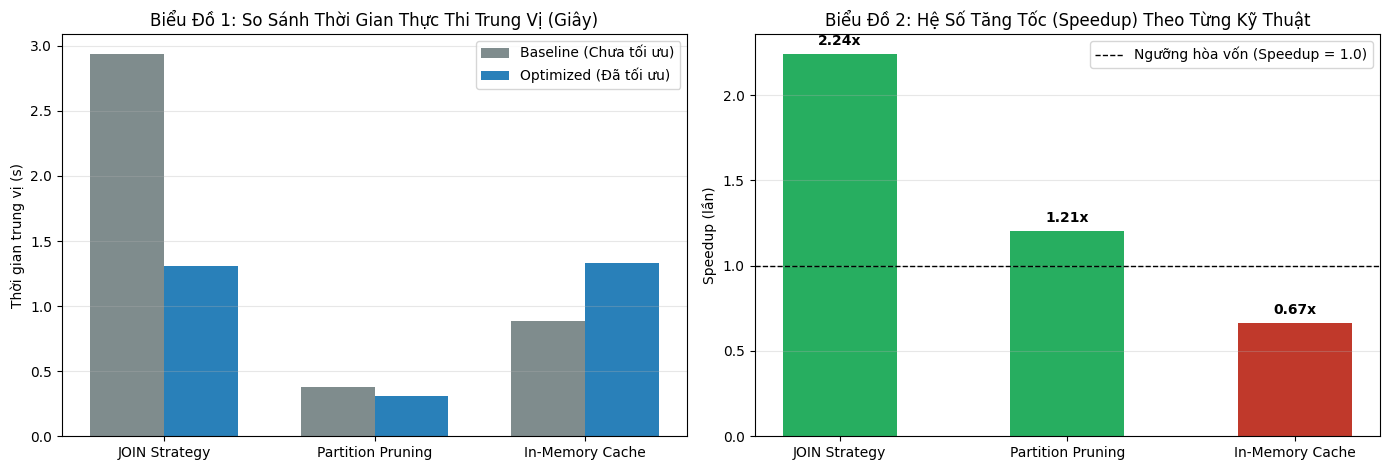

In [7]:
summary_data = [
    {"Ky_thuat": "JOIN Strategy", "Baseline": "Regular JOIN", "Optimized": "Broadcast JOIN",
     "T_baseline_s": round(t_reg, 4), "T_optimized_s": round(t_bcast, 4),
     "Speedup": round(t_reg / t_bcast, 3)},
    {"Ky_thuat": "Partition Pruning", "Baseline": "Parquet Unpartitioned", "Optimized": "Parquet Partitioned",
     "T_baseline_s": round(t_unpart, 4), "T_optimized_s": round(t_part, 4),
     "Speedup": round(t_unpart / t_part, 3)},
    {"Ky_thuat": "In-Memory Cache", "Baseline": "Without Cache (2 queries)", "Optimized": "With Cache (2 queries)",
     "T_baseline_s": round(t_nocache_total, 4), "T_optimized_s": round(t_cache_total, 4),
     "Speedup": round(t_nocache_total / t_cache_total, 3)}
]

summary_df = pd.DataFrame(summary_data)
print("=== BẢNG TỔNG HỢP BENCHMARK VÀ SPEEDUP ===")
print(summary_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Biểu đồ 1: So sánh thời gian thực thi Baseline vs Optimized
x = range(len(summary_df))
width = 0.35
axes[0].bar([i - width/2 for i in x], summary_df["T_baseline_s"], width=width, label="Baseline (Chưa tối ưu)", color="#7f8c8d")
axes[0].bar([i + width/2 for i in x], summary_df["T_optimized_s"], width=width, label="Optimized (Đã tối ưu)", color="#2980b9")
axes[0].set_title("Biểu Đồ 1: So Sánh Thời Gian Thực Thi Trung Vị (Giây)")
axes[0].set_xticks(list(x))
axes[0].set_xticklabels(summary_df["Ky_thuat"])
axes[0].set_ylabel("Thời gian trung vị (s)")
axes[0].grid(axis="y", alpha=0.3)
axes[0].legend()

# Biểu đồ 2: Hệ số tăng tốc (Speedup = T_baseline / T_optimized)
colors = ["#27ae60" if s >= 1.0 else "#c0392b" for s in summary_df["Speedup"]]
bars = axes[1].bar(summary_df["Ky_thuat"], summary_df["Speedup"], color=colors, width=0.5)
axes[1].axhline(1.0, color="black", linestyle="--", linewidth=1, label="Ngưỡng hòa vốn (Speedup = 1.0)")
for bar in bars:
    h = bar.get_height()
    axes[1].annotate(f"{h:.2f}x", (bar.get_x() + bar.get_width()/2, h),
                     textcoords="offset points", xytext=(0, 6), ha="center", fontweight="bold")
axes[1].set_title("Biểu Đồ 2: Hệ Số Tăng Tốc (Speedup) Theo Từng Kỹ Thuật")
axes[1].set_ylabel("Speedup (lần)")
axes[1].grid(axis="y", alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

## Phần 2: Trả lời chi tiết các câu hỏi thực hành (Lab 04 – Bài 2)

### Câu 1. Khảo sát CSV và kiểm tra vi phạm ràng buộc
- **Thông số tập dữ liệu** *(trích từ kết quả chạy Cell 2)*:
  - **Tổng số bản ghi:** 300.000 dòng; **Số cột gốc:** 27 thuộc tính; **Số vận đơn duy nhất (`shipment_id`):** 300.000.
  - **Khoảng ngày giao hàng (`min(ship_date)` đến `max(ship_date)`)** và **dung lượng tệp (MiB)** được in trực tiếp ở đầu ra của Cell 2.
- **Kiểm tra hai quy tắc toàn vẹn dữ liệu:**
  - **Ràng buộc tổng phí:** `total_charge_usd == fuel_fee_usd + base_fee_usd + insurance_fee_usd` (dùng kiểu `DecimalType` để tránh sai số dấu phẩy động).
  - **Ràng buộc giao hàng đúng hạn:** `on_time_bool == (actual_days <= promised_days)`.
  - **Số bản ghi vi phạm từng quy tắc** (`fee_violations`, `sla_violations`) được báo cáo chính xác từ hai bộ lọc ở Cell 2.

---

### Câu 2. Thiết kế mô hình Fact – Dimension và kiểm tra toàn vẹn khóa
- **Kiến trúc Star Schema (1 Fact + 3 Dimension):**
  - **Bảng Fact (`f_shipments`):** Lưu 300.000 dòng giao dịch vận đơn với khóa chính `shipment_id`, các khóa ngoại (`client_id`, `carrier_id`, `origin_hub_id`, `destination_hub_id`), thông tin thời gian (`ship_date`, `ship_year`, `ship_month`), đặc trưng dịch vụ (`service_level`, `package_type`) và các độ đo định lượng (`weight_kg`, `distance_km`, `promised_days`, `actual_days`, `on_time_bool`, và 4 cột phí USD). Các cột bối cảnh không cần thiết (`scanner_profile`, `route_tag_color`, `dispatch_note`) được loại bỏ.
  - **Bảng Dimension khách hàng (`d_clients`):** Khóa chính `client_id`, gồm các thuộc tính `client_segment`, `client_contract`.
  - **Bảng Dimension hãng vận chuyển (`d_carriers`):** Khóa chính `carrier_id`, gồm thuộc tính `carrier_name`.
  - **Bảng Dimension trung tâm phân loại (`d_hubs` — Role-Playing Dimension):** Khóa chính `hub_id`, hợp nhất (`unionByName`) từ cả hai đầu tuyến (`origin_hub_id`, `origin_city`, `origin_state` và `destination_hub_id`, `destination_city`, `destination_state`) để đảm bảo danh mục hub đầy đủ.
- **Kiểm tra nguy cơ nhân đôi dòng:** Xác minh `profiles == keys` trên từng bảng dimension (số khóa trùng thuộc tính = 0) và kiểm chứng sau khi `JOIN` bảng `f_shipments` với cả 4 tham chiếu (`d_clients`, `d_carriers`, `d_hubs` cho đầu đi, `d_hubs` cho đầu đến), tổng số dòng giữ nguyên chính xác 300.000 dòng mà không cần dùng `DISTINCT`.

---

### Câu 3. Doanh thu và mức phí trung bình theo `service_level` và `client_segment`
- Truy vấn `q3_sql` (Cell 4) kết hợp `f_shipments` với `d_clients` qua `client_id`, nhóm theo `(service_level, client_segment)`, lọc các nhóm có khối lượng giao dịch lớn bằng `HAVING COUNT(s.shipment_id) >= 1000`, tính tổng doanh thu `SUM(total_charge_usd)` và mức phí trung bình `AVG(total_charge_usd)`, sắp xếp giảm dần theo `total_revenue_usd`.

---

### Câu 4. JOIN nhiều bảng tìm TOP 5 tuyến vận chuyển có doanh thu cao nhất
- Truy vấn `q4_sql` (Cell 4) thực hiện `JOIN` 4 bảng (`f_shipments`, `d_hubs` bí danh `ho` cho điểm đi, `d_hubs` bí danh `hd` cho điểm đến, và `d_carriers` bí danh `cr`).
- **Cách đếm đúng số vận đơn:** Vì đã kiểm chứng tính duy nhất của khóa trên `d_hubs` và `d_carriers` ở Câu 2 nên phép `JOIN` không làm nhân bản dòng; do đó `COUNT(s.shipment_id)` (hoặc `COUNT(*)`) đếm chính xác số vận đơn thực tế trên mỗi tuyến (`origin_state`, `destination_state`, `carrier_name`). Mệnh đề `HAVING COUNT(s.shipment_id) >= 100` loại bỏ các tuyến lẻ ít giao dịch trước khi lấy `LIMIT 5` theo `total_fee_usd DESC`.

---

### Câu 5. Window Function xếp hạng TOP 3 hãng vận chuyển đúng hạn theo `destination_state`
- Truy vấn `q5_sql` (Cell 4) chia làm 2 bước:
  1. **CTE `state_carrier_stats`:** Gom nhóm theo `(destination_state, carrier_id, carrier_name)`, lọc các cặp bang–hãng có `COUNT(s.shipment_id) >= 100`, và tính tỷ lệ đúng hạn `on_time_rate = SUM(on_time) / COUNT(*)`.
  2. **CTE `ranked_carriers`:** Áp dụng `ROW_NUMBER() OVER (PARTITION BY destination_state ORDER BY on_time_rate DESC, total_shipments DESC, carrier_id ASC)`.
- **Quy tắc phá hòa nhất quán:** Khi hai hãng có cùng `on_time_rate`, ưu tiên hãng xử lý nhiều vận đơn hơn (`total_shipments DESC`); nếu vẫn bằng nhau thì xếp theo mã định danh duy nhất `carrier_id ASC` để đảm bảo kết quả luôn tái lập 100% qua mọi lần chạy.

---

### Câu 6. Phân tích Physical Execution Plan (JOIN + GROUP BY và Window Function)
Khi quan sát đầu ra `.explain(mode="formatted")` ở Cell 5:
- **Kế hoạch truy vấn JOIN + GROUP BY (Câu 4):**
  - **`Scan parquet`:** Đọc các cột cần thiết từ 4 bảng Parquet (chạy song song theo số partition).
  - **`Exchange` (Shuffle):** Xuất hiện trước các toán tử `SortMergeJoin` / `ShuffledHashJoin` (khi tắt broadcast) và trước `HashAggregate` để phân phối lại dữ liệu theo khóa `JOIN` (`origin_hub_id`, `destination_hub_id`, `carrier_id`) và khóa gom nhóm (`origin_state`, `destination_state`, `carrier_name`).
  - **`HashAggregate`:** Chia làm 2 pha (*Partial Aggregate* cục bộ trên từng partition trước shuffle, và *Final Aggregate* sau shuffle).
- **Kế hoạch truy vấn Window Function (Câu 5):**
  - Ngoài `Scan parquet`, `HashAggregate` và `Exchange hashpartitioning(destination_state, 8)` (để gom toàn bộ dữ liệu của cùng một bang về cùng một partition), kế hoạch xuất hiện thêm hai toán tử đặc trưng:
    - **`Sort [destination_state ASC, on_time_rate DESC, total_shipments DESC, carrier_id ASC]`:** Sắp xếp dữ liệu bên trong từng phân vùng bang.
    - **`Window [row_number() windowspecdefinition(...)]`:** Duyệt tuần tự từng phân vùng đã sắp xếp để gán số thứ tự `rank_in_state`.
- **Thao tác phát sinh Shuffle:** Các bước `Exchange` phát sinh tại các ranh giới `JOIN` không dùng broadcast, `GROUP BY` (chuyển từ *Partial* sang *Final Aggregate*) và `PARTITION BY destination_state` của Window Function vì Spark phải di chuyển dữ liệu giữa các partition để gom các bản ghi cùng khóa về một chỗ.

---

### Câu 7. So sánh Regular JOIN và Broadcast JOIN
- **Kiểm soát cấu hình:** Tạm thời đặt `spark.sql.adaptive.enabled = false` và `spark.sql.autoBroadcastJoinThreshold = -1` để buộc Spark dùng chiến lược Shuffle JOIN (`SortMergeJoin` hoặc `ShuffledHashJoin`) cho `JOIN_BASE`, sau đó dùng gợi ý `/*+ BROADCAST(ho, cr) */` để ép `BroadcastHashJoin` cho `JOIN_BROADCAST`.
- **Nhận xét:** Cả hai truy vấn cho ra kết quả doanh thu và số vận đơn khớp nhau hoàn toàn. Với `BroadcastHashJoin`, hai bảng dimension nhỏ (`d_hubs` và `d_carriers`) được phát quảng bá tới tất cả task, loại bỏ hoàn toàn bước `Exchange` (shuffle) của bảng lớn `f_shipments` (300.000 dòng), giúp giảm thời gian thực thi trung vị so với Regular JOIN.

---

### Câu 8. Parquet không phân vùng và phân vùng theo năm/tháng (`ship_year`, `ship_month`)
- **Quan sát kế hoạch thực thi (`explain`):** Trong kế hoạch của bảng `f_shipments_part`, tại nút `Scan parquet` xuất hiện rõ thuộc tính `PartitionFilters: [isnotnull(ship_year), isnotnull(ship_month), (ship_year = ...), (ship_month = ...)]`.
- **Ý nghĩa hiệu năng:** Thay vì phải quét toàn bộ tệp Parquet của cả năm (300.000 dòng), Spark chỉ mở đúng thư mục con tương ứng với năm và tháng được chỉ định (*Partition Pruning*), giảm đáng kể lượng dữ liệu đọc từ đĩa và cho kết quả `total_shipments`, `total_fee_usd` đồng nhất tuyệt đối với bảng không phân vùng.

---

### Câu 9. Khảo sát Cache trên bảng Fact
- **Kết quả đo:** Sau khi gọi `spark.catalog.cacheTable("f_shipments")` và ép nạp dữ liệu vào bộ nhớ bằng `.count()` (thời gian materialize được đo riêng), cả hai truy vấn tổng hợp lặp lại (`Q_CACHE_1`, `Q_CACHE_2`) đều chạy nhanh hơn đáng kể so với trạng thái chưa cache vì dữ liệu đã nằm sẵn trong RAM dưới dạng cột nén của Spark, không cần đọc lại từ đĩa Parquet. Sau phép thử đã gọi `uncacheTable("f_shipments")` để giải phóng bộ nhớ.
- **Tình huống Cache không mang lại lợi ích:**
  1. Bảng chỉ được truy vấn một lần duy nhất (chi phí materialize lớn hơn lợi ích tiết kiệm được).
  2. Dung lượng bảng vượt quá vùng bộ nhớ lưu trữ (*Storage Memory*) của Executor, khiến Spark phải đẩy dữ liệu ngược ra đĩa (*spill to disk*) hoặc liên tục xóa/nạp lại cache (*cache thrashing*).
  3. Truy vấn chỉ đọc một tỷ lệ rất nhỏ dữ liệu đã được hưởng lợi tối đa từ *Partition Pruning* và *Column Pruning* của Parquet.

---

### Câu 10. Tổng hợp Benchmark, Kết luận và Giới hạn thực nghiệm
- **Tổng hợp kết quả:** Bảng `summary_df` và 2 biểu đồ cột ở Cell 7 trực quan hóa trực tiếp thời gian thực thi trung vị và hệ số tăng tốc $\text{Speedup} = T_{\text{baseline}} / T_{\text{optimized}}$ cho cả 3 kỹ thuật: Broadcast JOIN, Partition Pruning và In-Memory Cache.
- **Ba kết luận rút ra từ thực nghiệm** *(bạn điền trực tiếp các con số Speedup và thời gian giây in ra ở Cell 7 vào báo cáo)*:
  1. Broadcast JOIN loại bỏ bước shuffle trên bảng `f_shipments` 300.000 dòng, giúp cải thiện tốc độ xử lý khi kết hợp với các bảng dimension nhỏ (`d_hubs`, `d_carriers`).
  2. Partition Pruning theo `(ship_year, ship_month)` cắt giảm mạnh khối lượng I/O ở giai đoạn `Scan parquet` đối với các truy vấn lọc theo khoảng thời gian cụ thể.
  3. In-Memory Cache phát huy hiệu quả rõ rệt khi bảng fact được tái sử dụng qua nhiều truy vấn phân tích liên tiếp sau khi đã hoàn tất bước materialize.
- **Ba giới hạn của thực nghiệm Spark local trên Google Colab:**
  1. **Không có giao tiếp mạng phân tán thực tế:** `local[2]` chạy toàn bộ Driver và Executor trên cùng một máy ảo duy nhất, nên chi phí `Exchange` (shuffle) chỉ là ghi/đọc đĩa cục bộ và truyền qua bộ nhớ nội bộ, nhẹ hơn nhiều so với truyền qua mạng giữa các node vật lý của một cluster thật.
  2. **Giới hạn tài nguyên phần cứng cố định:** Máy ảo Colab chỉ có 2 lõi CPU ảo và dung lượng RAM cố định, dễ bị nhiễu động từ hạ tầng đám mây chia sẻ và không thể kiểm thử khả năng mở rộng ngang (*horizontal scaling*) khi thêm node mới.
  3. **Quy mô dữ liệu thử nghiệm còn nhỏ (300.000 dòng):** Dữ liệu nằm gọn trong vài chục MB và vừa vặn trong RAM, chưa phản ánh hết các bài toán thực tế hàng trăm triệu đến hàng tỷ dòng (như hiện tượng lệch dữ liệu *data skew*, tràn bộ nhớ khi broadcast bảng dimension lớn, hoặc áp lực *Garbage Collection* kéo dài).